In [8]:
from qutip import *
import numpy as np
import matplotlib.pyplot as plt

N_cav = 30 #(truncado)
N_atomos = 15
epsilon = .3
lamda = 1

tiempo = 30
pasos = 300
res = {}
j = N_atomos/2
g_eff = lamda / 2*(np.sqrt(N_atomos)) # Acoplamiento

a = tensor(destroy(N_cav), qeye(int(2*j +1)))
res["a"] = a
#Ahora definimos a los operadores colectivos
J_z = tensor(qeye(N_cav), jmat(j, "z"))
J_p = tensor(qeye(N_cav), jmat(j, "+"))
J_m = tensor(qeye(N_cav), jmat(j, "-"))
res.update({"J_z":J_z, "J_m":J_m, "J_p":J_p})
#Generamos estado inicial
estado_inicial_cavidad = basis(N_cav, 0)
estado_inicial_atomico = basis(int(2*j +1), 0)
res["estado inicial"] =  tensor(estado_inicial_cavidad,estado_inicial_atomico)

tlist = np.linspace(0, tiempo, pasos)

rho0 = res["estado inicial"]

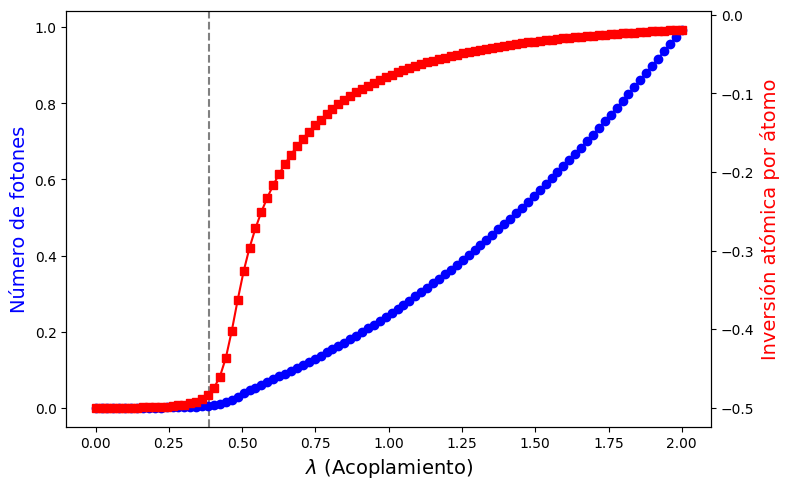

Text(0, 0.5, 'Inversión Atómica por Átomo')

In [9]:
lamdas = np.linspace(0, 2, 100)  # rango alrededor de lambda_c

# Parte del Hamiltoniano que no depende del acoplamiento
H0 = a.dag() @ a + (epsilon / 2) * J_z

n_fotones = []
inversion = []

for l in lamdas:
    # acoplamiento efectivo en función del parámetro de control
    g_eff = l / (2 * np.sqrt(N_atomos))
    H = H0 + g_eff * (a + a.dag()) * (J_p + J_m)

    # Estado fundamental del Hamiltoniano
    en, gs = H.groundstate()

    # Observables en el estado fundamental
    n_fotones.append(expect(a.dag() @ a, gs) / N_atomos)
    inversion.append(expect(J_z, gs) / N_atomos)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Punto crítico teórico del modelo de Dicke
lambda_c = np.sqrt(epsilon/2)
ax1.axvline(lambda_c, color='gray', linestyle='--', label='Punto crítico')

ax1.plot(lamdas, n_fotones, 'bo-', label='Fotones')
ax1.set_xlabel(r'$\lambda$ (Acoplamiento)', fontsize=14)
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión atómica por átomo', color='r', fontsize=14)

plt.tight_layout()
plt.show()
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión Atómica por Átomo', color='r', fontsize=14)
